# TraCE video QA: concept matching, contributions, intervention

This notebook only calls functions of the `src` package. It needs a released VQA bundle (`checkpoints/vqa/<dataset>`) and a cached InternVideo2 feature split (`video_features.pt`, `text_features.pt`, `sample_index.json`).

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))
import torch
from src.vqa import TraCEVQA
from src.vqa.data import load_split
from src.explain.intervention import vqa_removal
from src.explain.visualize import plot_vqa_matrix

DATASET = 'ucf101'
BUNDLE = f'../checkpoints/vqa/{DATASET}'
SPLIT = f'../features/vqa/{DATASET}/val'

## Load the model and evaluate (Eq. 5 scoring)

In [2]:
model = TraCEVQA.load(BUNDLE)
print(model.vocab.group_sizes(), {g: round(float(model.group_weight(g)), 2) for g in model.groups})
d = load_split(SPLIT)
pred = model.predict(d.video_feats, d.option_feats, d.option_mask)
print('top-1 accuracy: %.2f%% (%d questions)' % (100 * (pred == d.answers).float().mean(), len(d)))

{'trajectory': 759, 'object': 1181, 'scene': 615} {'trajectory': 17.05, 'object': 279.39, 'scene': 269.88}


top-1 accuracy: 99.68% (3783 questions)


## Explain one answer

A concept contributes `exp(gamma_g) * p_gj[m]` to candidate j if it is in the top-5 of its group for that candidate, otherwise 0. The contributions sum exactly to the candidate score (no bias term).

candidates: ['JavelinThrow', 'WallPushups', 'ApplyEyeMakeup', 'BodyWeightSquats', 'FieldHockeyPenalty']
answer: ApplyEyeMakeup | prediction: ApplyEyeMakeup
scores: [11.354, 12.242, 33.634, 10.886, 9.477]
contribution sum of prediction: 33.6336 (score 33.6336)
trajectory [('trajectory_013', 3.654), ('trajectory_131', 3.217), ('trajectory_005', 2.45), ('trajectory_125', 0.61), ('trajectory_129', 0.162)]
object [('eyeliner', 2.964), ('lip pencil', 2.144), ('window blind', 2.086), ('goggles', 1.863), ('glasses', 1.676)]
scene [('circular windows', 3.215), ('window', 2.658), ('mirror', 2.392), ('screen', 2.373), ('studio', 2.168)]


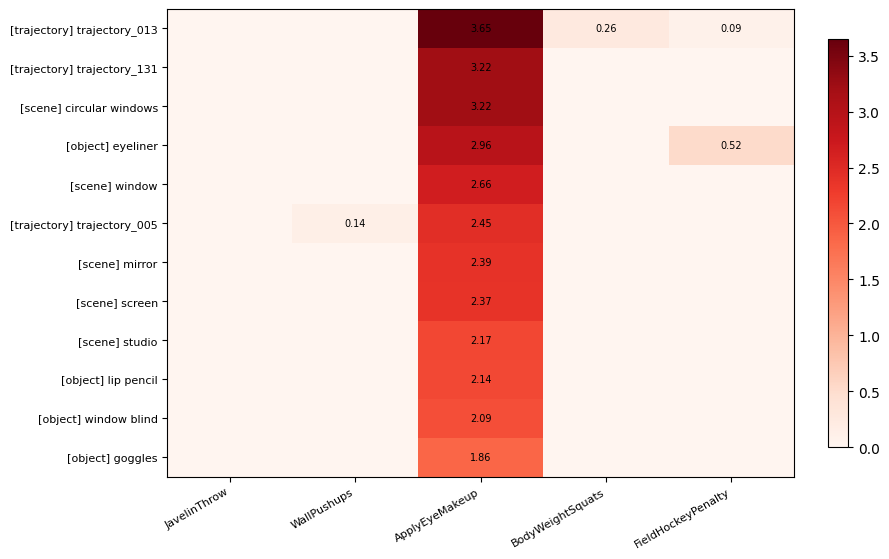

In [3]:
i = 5
n = int(d.option_mask[i].sum())
e = model.explain(d.video_feats[i], d.option_feats[i, :n], candidates=d.options[i])
print('candidates:', d.options[i])
print('answer:', d.options[i][d.answers[i]], '| prediction:', d.options[i][e.pred])
print('scores:', [round(float(s), 3) for s in e.scores])
print('contribution sum of prediction: %.4f (score %.4f)' % (e.contributions[e.pred].sum(), e.scores[e.pred]))
for g in model.vocab.groups:
    print(g, [(nm, round(v, 3)) for _, _, nm, v in model.top_concepts(e.contributions[e.pred], 5, g)])
used = sorted(torch.nonzero(e.contributions.sum(0)).flatten().tolist(), key=lambda c: -float(e.contributions[e.pred, c]))[:12]
plot_vqa_matrix(e.contributions[:, used].T.numpy(), [model.vocab.label(c) for c in used], d.options[i]);

## Intervention on video-side concepts

Removing a concept sets its raw video activation to 0; ReLU, normalization and top-5 matching are then recomputed for every candidate.

In [4]:
top3 = [cid for cid, *_ in model.top_concepts(e.contributions[e.pred], 3, 'trajectory')]
before, after = model.score_with_intervention(d.video_feats[i:i+1], d.option_feats[i:i+1, :n], top3)
for j, c in enumerate(d.options[i]):
    print(f'{c:30s} {before[0, j]:7.3f} -> {after[0, j]:7.3f}')

JavelinThrow                    11.354 ->  11.535
WallPushups                     12.242 ->  12.646
ApplyEyeMakeup                  33.634 ->  25.050
BodyWeightSquats                10.886 ->  10.863
FieldHockeyPenalty               9.477 ->   9.580


## Top-K vs. Random-K trajectory-concept removal

In [5]:
res = vqa_removal(model, d.video_feats, d.option_feats, d.answers, d.option_mask, ks=[5, 10], seed=0)
for k in [5, 10]:
    print(f"K={k}: flip top {res[f'top-{k}']['flip_rate']*100:.2f}%  random {res[f'random-{k}']['flip_rate']*100:.2f}%  bottom {res[f'bottom-{k}']['flip_rate']*100:.2f}%")

K=5: flip top 0.69%  random 0.00%  bottom 0.00%
K=10: flip top 0.69%  random 0.00%  bottom 0.00%
